# Exploratory Data Analysis (EDA) Project
# Phase 2 — 2D Statistical Analysis

**Name:** ANINDO PRITOM BARUA  
**Registration Number:** 23BDS0328  
**Course:** Exploratory Data Analysis (EDA)  
**Dataset:** Indian Food Dataset

## Objective

The objective of this notebook is to perform two-dimensional (2D) statistical analysis on the Indian Food dataset. The relationships between pairs of variables will be examined using covariance, Pearson correlation, Spearman correlation, regression analysis, and appropriate graphical techniques.

The analysis will focus on identifying the direction and strength of relationships between numerical variables and comparing numerical variables across categorical groups.

PHASE 2 - 2D STATISTICAL ANALYSIS

Dataset loaded successfully.
Rows    : 255
Columns : 20

NUMERICAL VARIABLES USED
['prep_time', 'cook_time', 'total_time']

1. COVARIANCE MATRIX


,prep_time,cook_time,total_time
prep_time,5264.142288,504.668133,5768.810421
cook_time,504.668133,2329.572950,2834.241084
total_time,5768.810421,2834.241084,8603.051505



2. PEARSON CORRELATION MATRIX


,prep_time,cook_time,total_time
prep_time,1.000000,0.144113,0.857228
cook_time,0.144113,1.000000,0.633100
total_time,0.857228,0.633100,1.000000



3. SPEARMAN CORRELATION MATRIX


,prep_time,cook_time,total_time
prep_time,1.000000,0.473432,0.776243
cook_time,0.473432,1.000000,0.861485
total_time,0.776243,0.861485,1.000000



4. CORRELATION COMPARISON


,Pearson,Spearman
prep_time,1.000000,1.000000
cook_time,0.144113,0.473432
total_time,0.857228,0.776243


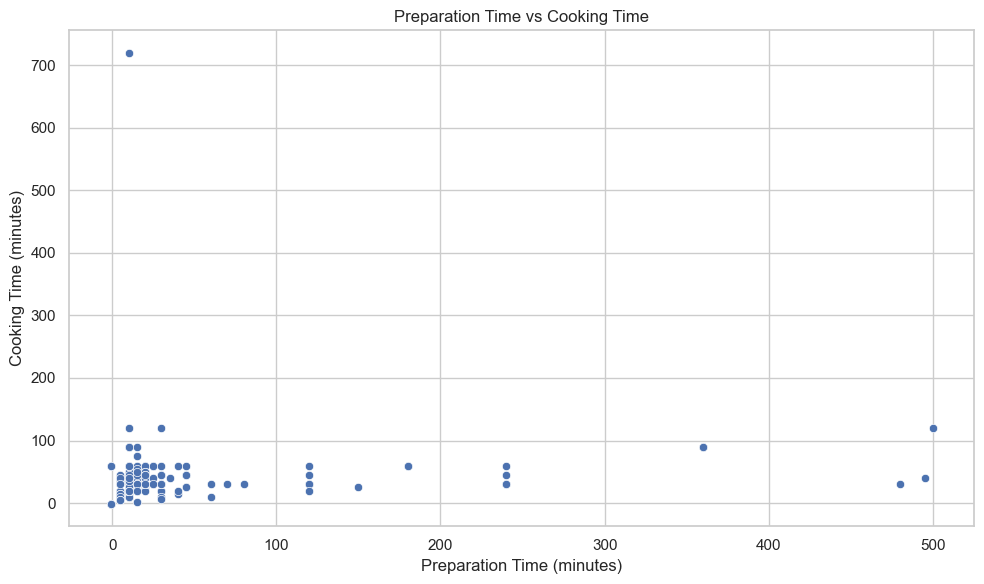

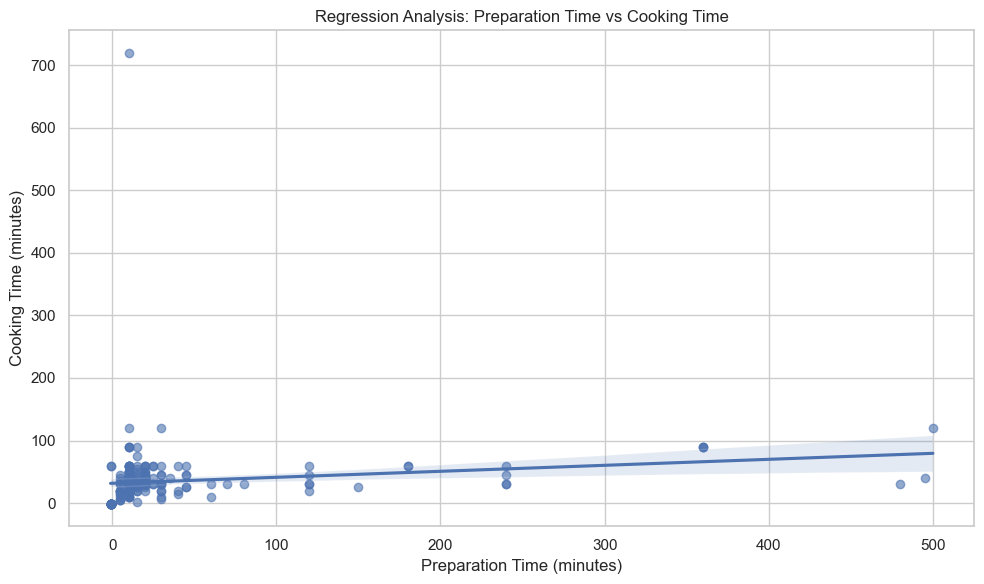


5. SIMPLE LINEAR REGRESSION
Slope       : 0.0959
Intercept   : 31.5473
R-value     : 0.1441
R-squared   : 0.0208
P-value     : 0.021334
Std. Error  : 0.0414

Regression Equation:
Cooking Time = 31.5473 + (0.0959 × Preparation Time)


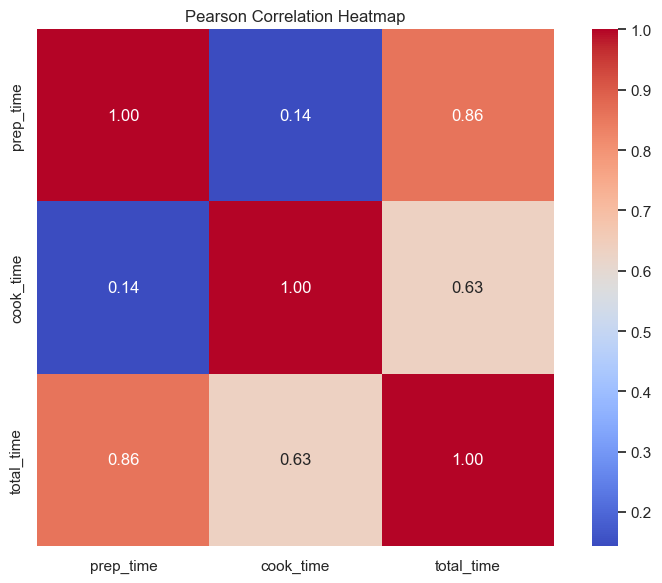

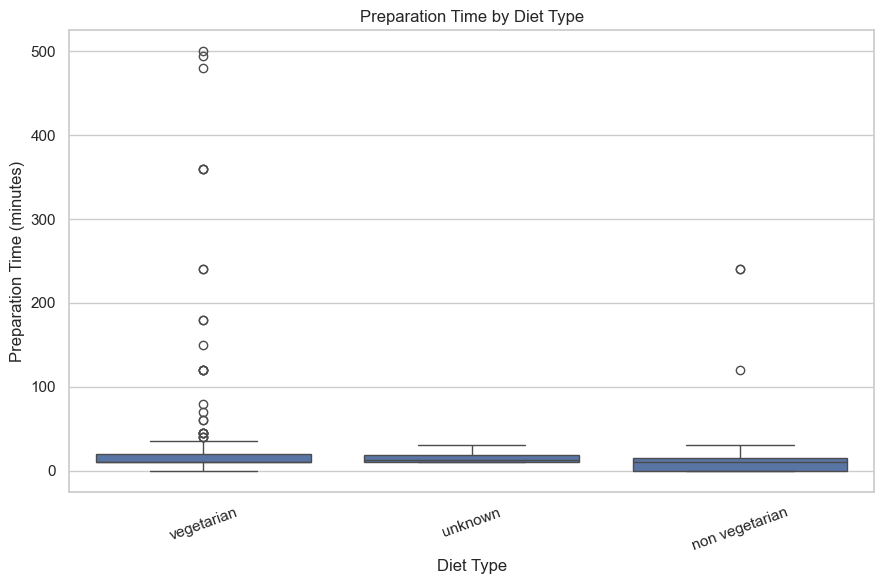

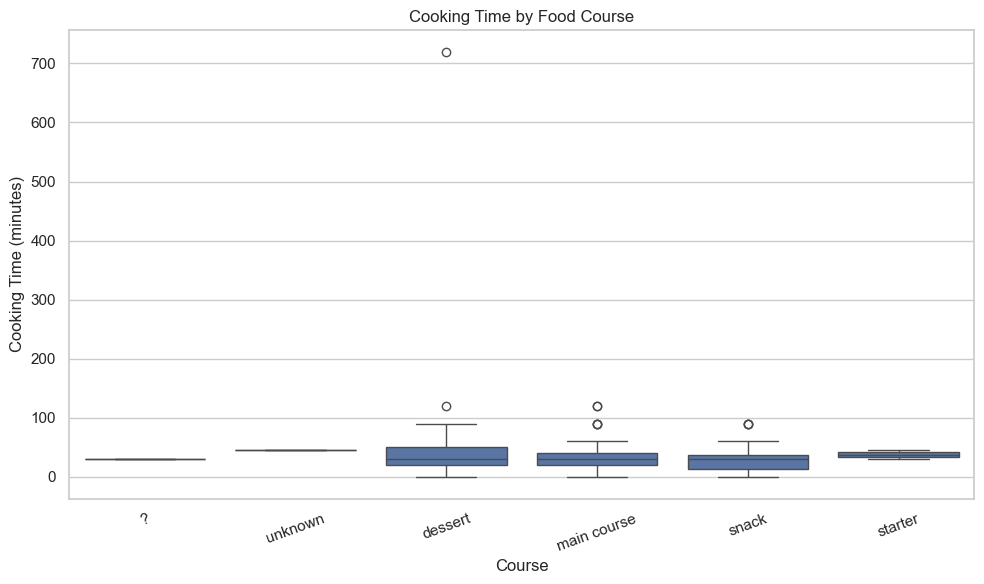


6. PEARSON CORRELATION SIGNIFICANCE TEST
Pearson correlation : 0.1441
P-value             : 0.021334
The correlation is statistically significant at the 5% significance level.

7. SPEARMAN CORRELATION SIGNIFICANCE TEST
Spearman correlation : 0.4734
P-value              : 0.0
The Spearman relationship is statistically significant at the 5% significance level.

FINAL 2D STATISTICAL SUMMARY
Pearson correlation between preparation and cooking time: 0.1441
Spearman correlation between preparation and cooking time: 0.4734
R-squared from linear regression: 0.0208

2D STATISTICAL ANALYSIS COMPLETED


In [1]:
# ============================================================
# PHASE 2 - 2D STATISTICAL ANALYSIS
# Name        : ANINDO PRITOM BARUA
# Registration: 23BDS0328
# Dataset     : Indian Food Dataset
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# ------------------------------------------------------------
# 1. Load the transformed dataset
# ------------------------------------------------------------

file_path = "indian_food_transformed.csv"

df = pd.read_csv(file_path)

print("=" * 75)
print("PHASE 2 - 2D STATISTICAL ANALYSIS")
print("=" * 75)

print("\nDataset loaded successfully.")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

sns.set_theme(style="whitegrid")


# ------------------------------------------------------------
# 2. Select numerical variables
# ------------------------------------------------------------

numerical_columns = [
    "prep_time",
    "cook_time",
    "total_time"
]

print("\nNUMERICAL VARIABLES USED")
print("=" * 75)
print(numerical_columns)


# ------------------------------------------------------------
# 3. Covariance Matrix
# ------------------------------------------------------------

print("\n1. COVARIANCE MATRIX")
print("=" * 75)

covariance_matrix = df[numerical_columns].cov()

display(covariance_matrix)


# ------------------------------------------------------------
# 4. Pearson Correlation Matrix
# ------------------------------------------------------------

print("\n2. PEARSON CORRELATION MATRIX")
print("=" * 75)

pearson_correlation = df[numerical_columns].corr(
    method="pearson"
)

display(pearson_correlation)


# ------------------------------------------------------------
# 5. Spearman Correlation Matrix
# ------------------------------------------------------------

print("\n3. SPEARMAN CORRELATION MATRIX")
print("=" * 75)

spearman_correlation = df[numerical_columns].corr(
    method="spearman"
)

display(spearman_correlation)


# ------------------------------------------------------------
# 6. Pearson and Spearman correlation comparison
# ------------------------------------------------------------

print("\n4. CORRELATION COMPARISON")
print("=" * 75)

comparison = pd.DataFrame({
    "Pearson": pearson_correlation[
        "prep_time"
    ],
    "Spearman": spearman_correlation[
        "prep_time"
    ]
})

display(comparison)


# ------------------------------------------------------------
# 7. Visualization 1
# Scatter Plot - Preparation Time vs Cooking Time
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="prep_time",
    y="cook_time"
)

plt.title(
    "Preparation Time vs Cooking Time"
)
plt.xlabel("Preparation Time (minutes)")
plt.ylabel("Cooking Time (minutes)")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. Visualization 2
# Regression Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="prep_time",
    y="cook_time",
    scatter_kws={"alpha": 0.6}
)

plt.title(
    "Regression Analysis: Preparation Time vs Cooking Time"
)
plt.xlabel("Preparation Time (minutes)")
plt.ylabel("Cooking Time (minutes)")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Simple Linear Regression
# ------------------------------------------------------------

print("\n5. SIMPLE LINEAR REGRESSION")
print("=" * 75)

x = df["prep_time"].dropna()
y = df.loc[x.index, "cook_time"]

slope, intercept, r_value, p_value, std_err = stats.linregress(
    x,
    y
)

print("Slope       :", round(slope, 4))
print("Intercept   :", round(intercept, 4))
print("R-value     :", round(r_value, 4))
print("R-squared   :", round(r_value ** 2, 4))
print("P-value     :", round(p_value, 6))
print("Std. Error  :", round(std_err, 4))

print(
    "\nRegression Equation:"
)
print(
    f"Cooking Time = {intercept:.4f} + "
    f"({slope:.4f} × Preparation Time)"
)


# ------------------------------------------------------------
# 10. Visualization 3
# Correlation Heatmap
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

sns.heatmap(
    pearson_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True
)

plt.title(
    "Pearson Correlation Heatmap"
)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Visualization 4
# Preparation Time by Diet
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="diet",
    y="prep_time"
)

plt.title(
    "Preparation Time by Diet Type"
)
plt.xlabel("Diet Type")
plt.ylabel("Preparation Time (minutes)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Visualization 5
# Cooking Time by Course
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="course",
    y="cook_time"
)

plt.title(
    "Cooking Time by Food Course"
)
plt.xlabel("Course")
plt.ylabel("Cooking Time (minutes)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Statistical Test
# Pearson correlation significance test
# ------------------------------------------------------------

print("\n6. PEARSON CORRELATION SIGNIFICANCE TEST")
print("=" * 75)

pearson_r, pearson_p = stats.pearsonr(
    x,
    y
)

print("Pearson correlation :", round(pearson_r, 4))
print("P-value             :", round(pearson_p, 6))

if pearson_p < 0.05:
    print(
        "The correlation is statistically significant "
        "at the 5% significance level."
    )
else:
    print(
        "The correlation is not statistically significant "
        "at the 5% significance level."
    )


# ------------------------------------------------------------
# 14. Statistical Test
# Spearman correlation significance test
# ------------------------------------------------------------

print("\n7. SPEARMAN CORRELATION SIGNIFICANCE TEST")
print("=" * 75)

spearman_r, spearman_p = stats.spearmanr(
    x,
    y
)

print("Spearman correlation :", round(spearman_r, 4))
print("P-value              :", round(spearman_p, 6))

if spearman_p < 0.05:
    print(
        "The Spearman relationship is statistically significant "
        "at the 5% significance level."
    )
else:
    print(
        "The Spearman relationship is not statistically significant "
        "at the 5% significance level."
    )


# ------------------------------------------------------------
# 15. Final 2D Summary
# ------------------------------------------------------------

print("\nFINAL 2D STATISTICAL SUMMARY")
print("=" * 75)

print(
    f"Pearson correlation between preparation and cooking time: "
    f"{pearson_r:.4f}"
)

print(
    f"Spearman correlation between preparation and cooking time: "
    f"{spearman_r:.4f}"
)

print(
    f"R-squared from linear regression: "
    f"{r_value ** 2:.4f}"
)

print("\n" + "=" * 75)
print("2D STATISTICAL ANALYSIS COMPLETED")
print("=" * 75)

## Conclusion

Two-dimensional statistical analysis was successfully performed on the Indian Food dataset.

Covariance, Pearson correlation, and Spearman correlation were calculated to measure the strength and direction of relationships between numerical variables. Linear regression was also performed to model the relationship between preparation time and cooking time.

Scatter plots, regression plots, correlation heatmaps, and boxplots were used to visually examine relationships between numerical and categorical variables. Statistical significance tests were additionally performed for the Pearson and Spearman correlations.

The analysis provides a detailed understanding of relationships between pairs of variables and establishes a foundation for the three-dimensional statistical analysis in the next stage.